# Chapter 5, robot motion: run first, read second

This notebook is the hands-on companion of chapter 5 of *Probabilistic Robotics* (Thrun, Burgard, Fox, 2005), book pages 117 to 148. Run it before you read the chapter. Every plot below answers a question that the text then explains.

The chapter gives two motion models, and each model in two forms:

| Model | Closed form, density $p(x_t \mid u_t, x_{t-1})$ | Sampler, draws $x_t \sim p(x_t \mid u_t, x_{t-1})$ | Control $u_t$ |
| --- | --- | --- | --- |
| Velocity | Table 5.1 (p. 123) | Table 5.3 (p. 124) | commanded $(v, \omega)$ for a time $\Delta t$ |
| Odometry | Table 5.5 (p. 134) | Table 5.6 (p. 136) | two odometry poses $(\bar x_{t-1}, \bar x_t)$ |

A histogram filter (chapter 4) needs the closed form, a particle filter needs only the sampler. Part 1 implements all four tables, checks that density and sampler describe the same distribution, and draws the banana-shaped clouds for different noise parameters $\alpha$. Part 2 applies the odometry model to a real Spot trajectory from Paper 2, where Spot walks sideways. The whole notebook runs in less than a minute.

```bash
cd src/courses-free/probabilistic_robotics
uv run jupyter lab notebooks/ch05_motion_models.ipynb
# or headless, rewriting the outputs in place:
uv run jupyter nbconvert --to notebook --execute --inplace notebooks/ch05_motion_models.ipynb
```

The interactive version of the clouds (radio buttons for the presets) is `uv run python demos/ch05_motion_models.py`. The $\alpha$ values in this notebook are illustrative, the book gives none.

In [1]:
import math
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

rng = np.random.default_rng(5)
plt.rcParams["figure.dpi"] = 90


def wrap(a):
    # Angles into [-pi, pi). The book warns about this on p. 135.
    return (a + np.pi) % (2 * np.pi) - np.pi


def prob(a, b2):
    # Table 5.2, line 2: zero-mean normal density of the error a with variance b^2.
    b2 = np.maximum(b2, 1e-12)
    return np.exp(-0.5 * a**2 / b2) / np.sqrt(2 * np.pi * b2)


def sample(b2, size=None):
    # Table 5.4: a zero-mean normal sample with variance b^2 (the book's sample(b^2)).
    return rng.normal(0.0, np.sqrt(b2), size)

## Part 1. Run the four tables

### The velocity model (Tables 5.1 and 5.3)

The closed form reconstructs the circle that leads from $x_{t-1}$ to the candidate $x_t$, computes the speeds $(\hat v, \hat\omega)$ a perfect robot would have needed plus the extra final turn $\hat\gamma$, and scores the three errors. Line 7 of Table 5.1 as printed gives $\hat v$ the sign of $\Delta\theta$. That is wrong for a robot that drives forward while turning right. The code below uses the signed radius $\lambda$ of eq. 5.17 instead, and the printed version is kept for the check at the end of Part 1.

In [2]:
def motion_model_velocity(xt, u, xprev, a, dt, printed_line7=False):
    # Table 5.1. xt has shape (3, ...) so that a whole grid of candidate poses goes in at once.
    x, y, th = xprev
    xp, yp, thp = xt
    v, w = u
    with np.errstate(divide="ignore", invalid="ignore"):
        mu = 0.5 * ((x - xp) * np.cos(th) + (y - yp) * np.sin(th)) / ((y - yp) * np.cos(th) - (x - xp) * np.sin(th))  # line 2
    mu = np.clip(np.nan_to_num(mu), -1e6, 1e6)  # straight motion: infinite radius
    xs = (x + xp) / 2 + mu * (y - yp)  # line 3, circle center
    ys = (y + yp) / 2 + mu * (xp - x)  # line 4
    rs = np.hypot(x - xs, y - ys)  # line 5, radius, always positive
    dth = wrap(np.arctan2(yp - ys, xp - xs) - np.arctan2(y - ys, x - xs))  # line 6
    w_hat = dth / dt  # line 8
    if printed_line7:
        v_hat = dth / dt * rs  # line 7 as printed
    else:
        lam = (ys - y) * np.cos(th) - (xs - x) * np.sin(th)  # signed radius, eq. 5.17
        v_hat = w_hat * lam
    g_hat = wrap(thp - th) / dt - w_hat  # line 9, the final rotation
    return (prob(v - v_hat, a[0] * v**2 + a[1] * w**2)  # line 10
            * prob(w - w_hat, a[2] * v**2 + a[3] * w**2)
            * prob(g_hat, a[4] * v**2 + a[5] * w**2))


def sample_motion_model_velocity(u, xprev, a, dt, n):
    # Table 5.3 for n samples at once. xprev has shape (3,) or (3, n).
    x, y, th = xprev
    v, w = u
    v_hat = v + sample(a[0] * v**2 + a[1] * w**2, n)  # line 2
    w_hat = w + sample(a[2] * v**2 + a[3] * w**2, n)  # line 3
    g_hat = sample(a[4] * v**2 + a[5] * w**2, n)  # line 4
    r = v_hat / np.where(np.abs(w_hat) < 1e-9, 1e-9, w_hat)
    xp = x - r * np.sin(th) + r * np.sin(th + w_hat * dt)  # line 5
    yp = y + r * np.cos(th) - r * np.cos(th + w_hat * dt)  # line 6
    thp = th + w_hat * dt + g_hat * dt  # line 7
    return np.vstack((xp, yp, thp))

### The odometry model (Tables 5.5 and 5.6)

The odometry reading is turned into three motions: turn by $\delta_{rot1}$, drive $\delta_{trans}$ straight, turn by $\delta_{rot2}$. Noise enters each of the three. When the robot hardly moves, $\delta_{rot1}$ is the direction of a vector of length zero, so (like Nav2 AMCL) we set it to zero below 1 cm.

In [3]:
MIN_TRANS = 0.01  # m, below this the direction of travel is meaningless


def odometry_deltas(p0, p1):
    # Table 5.5 lines 2 to 4 (and 5 to 7 with the candidate poses). Inputs have shape (3, ...).
    trans = np.hypot(p1[0] - p0[0], p1[1] - p0[1])  # line 3
    rot1 = np.where(trans < MIN_TRANS, 0.0, wrap(np.arctan2(p1[1] - p0[1], p1[0] - p0[0]) - p0[2]))  # line 2
    rot2 = wrap(p1[2] - p0[2] - rot1)  # line 4
    return rot1, trans, rot2


def motion_model_odometry(xt, u, xprev, a):
    # Table 5.5. u = (odometry pose at t-1, odometry pose at t).
    r1, tr, r2 = odometry_deltas(*u)  # lines 2 to 4, from the odometry
    r1h, trh, r2h = odometry_deltas(xprev, xt)  # lines 5 to 7, from the candidate
    p1 = prob(wrap(r1 - r1h), a[0] * r1h**2 + a[1] * trh**2)  # line 8
    p2 = prob(tr - trh, a[2] * trh**2 + a[3] * r1h**2 + a[3] * r2h**2)  # line 9
    p3 = prob(wrap(r2 - r2h), a[0] * r2h**2 + a[1] * trh**2)  # line 10
    return p1 * p2 * p3  # line 11


def sample_motion_model_odometry(u, xprev, a, n):
    # Table 5.6 for n samples at once.
    r1, tr, r2 = odometry_deltas(*u)  # lines 2 to 4
    r1h = r1 - sample(a[0] * r1**2 + a[1] * tr**2, n)  # line 5
    trh = tr - sample(a[2] * tr**2 + a[3] * r1**2 + a[3] * r2**2, n)  # line 6
    r2h = r2 - sample(a[0] * r2**2 + a[1] * tr**2, n)  # line 7
    x, y, th = xprev
    return np.vstack((x + trh * np.cos(th + r1h), y + trh * np.sin(th + r1h), th + r1h + r2h))  # lines 8 to 10

### Density and sampler describe the same distribution

One motion: start at the origin facing $+x$, drive about 2 m while turning left. For the closed form we evaluate the density on a grid of candidate poses $(x, y, \theta)$ and add up over $\theta$, which gives the density of the position alone (the book's Figs. 5.3 and 5.8 show the same projection). For the sampler we draw 20 000 samples. If both implement the same model, about 90 % of the samples must fall inside the region that holds 90 % of the density.

Look at the integral in the titles. It is not 1. Tables 5.1 and 5.5 multiply the densities of three *errors* (speed, turn rate, final turn, or rot1, trans, rot2). They are not normalized over the pose $(x', y', \theta')$, because the change of variables from errors to pose has a Jacobian that the book leaves out. For the odometry model the Jacobian is simply $\hat\delta_{trans}$ (polar coordinates), so dividing by it gives a proper pose density, and the cell prints its integral too. A filter does not care: Bayes normalizes anyway.

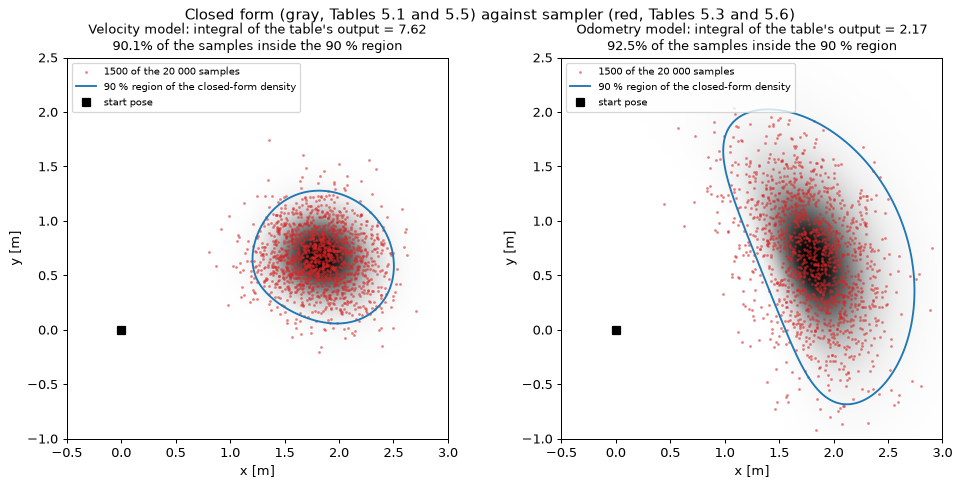

odometry model divided by the Jacobian delta_trans: integral = 1.046


In [4]:
START = np.array([0.0, 0.0, 0.0])
V, OMEGA, DT = 1.0, 0.35, 2.0  # velocity control
ODO = (START, np.array([2 * math.cos(0.35), 2 * math.sin(0.35), 0.7]))  # odometry poses: rot1 = 0.35, trans = 2 m, rot2 = 0.35
A_VEL = (0.02, 0.02, 0.02, 0.02, 0.01, 0.01)
A_ODO = (0.02, 0.02, 0.02, 0.02)

xs = np.linspace(-0.5, 3.0, 141)
ys = np.linspace(-1.0, 2.5, 141)
ths = np.linspace(-np.pi, np.pi, 241, endpoint=False)
GX, GY, GT = np.meshgrid(xs, ys, ths, indexing="ij")
grid = np.stack((GX, GY, GT))
cell = (xs[1] - xs[0]) * (ys[1] - ys[0]) * (ths[1] - ths[0])

models = {
    "Velocity model": (motion_model_velocity(grid, (V, OMEGA), START, A_VEL, DT),
                       sample_motion_model_velocity((V, OMEGA), START, A_VEL, DT, 20000)),
    "Odometry model": (motion_model_odometry(grid, ODO, START, A_ODO),
                       sample_motion_model_odometry(ODO, START, A_ODO, 20000)),
}

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, (name, (dens, samples)) in zip(axes, models.items()):
    pxy = dens.sum(axis=2) * (ths[1] - ths[0])  # marginal over theta
    mass = dens.sum() * cell
    order = np.sort(pxy.ravel())[::-1]
    level90 = order[np.searchsorted(np.cumsum(order) / order.sum(), 0.9)]
    ix = np.clip(np.searchsorted(xs, samples[0]), 0, len(xs) - 1)
    iy = np.clip(np.searchsorted(ys, samples[1]), 0, len(ys) - 1)
    inside = np.mean(pxy[ix, iy] >= level90)
    ax.imshow(pxy.T, origin="lower", extent=(xs[0], xs[-1], ys[0], ys[-1]), cmap="Greys")
    ax.scatter(samples[0, :1500], samples[1, :1500], s=2, c="tab:red", alpha=0.4, label="1500 of the 20 000 samples")
    ax.contour(xs, ys, pxy.T, levels=[level90], colors="tab:blue", linewidths=1.5)
    ax.plot([], [], color="tab:blue", label="90 % region of the closed-form density")
    ax.plot(0, 0, "ks", label="start pose")
    ax.set_title(f"{name}: integral of the table's output = {mass:.2f}\n{inside:.1%} of the samples inside the 90 % region", fontsize=10)
    ax.set_xlabel("x [m]")
    ax.set_ylabel("y [m]")
    ax.legend(loc="upper left", fontsize=8)
fig.suptitle("Closed form (gray, Tables 5.1 and 5.5) against sampler (red, Tables 5.3 and 5.6)")
plt.show()

trh = odometry_deltas(START, grid)[1]
pose_density = models["Odometry model"][0] / np.maximum(trh, 1e-9)
print(f"odometry model divided by the Jacobian delta_trans: integral = {pose_density.sum() * cell:.3f}")

### The banana: what each $\alpha$ does

Three noise presets for the same motion as above, 1000 samples each. Look at the shape before you read why: which preset bends the cloud along the arc, and which one stretches it along the direction of travel?

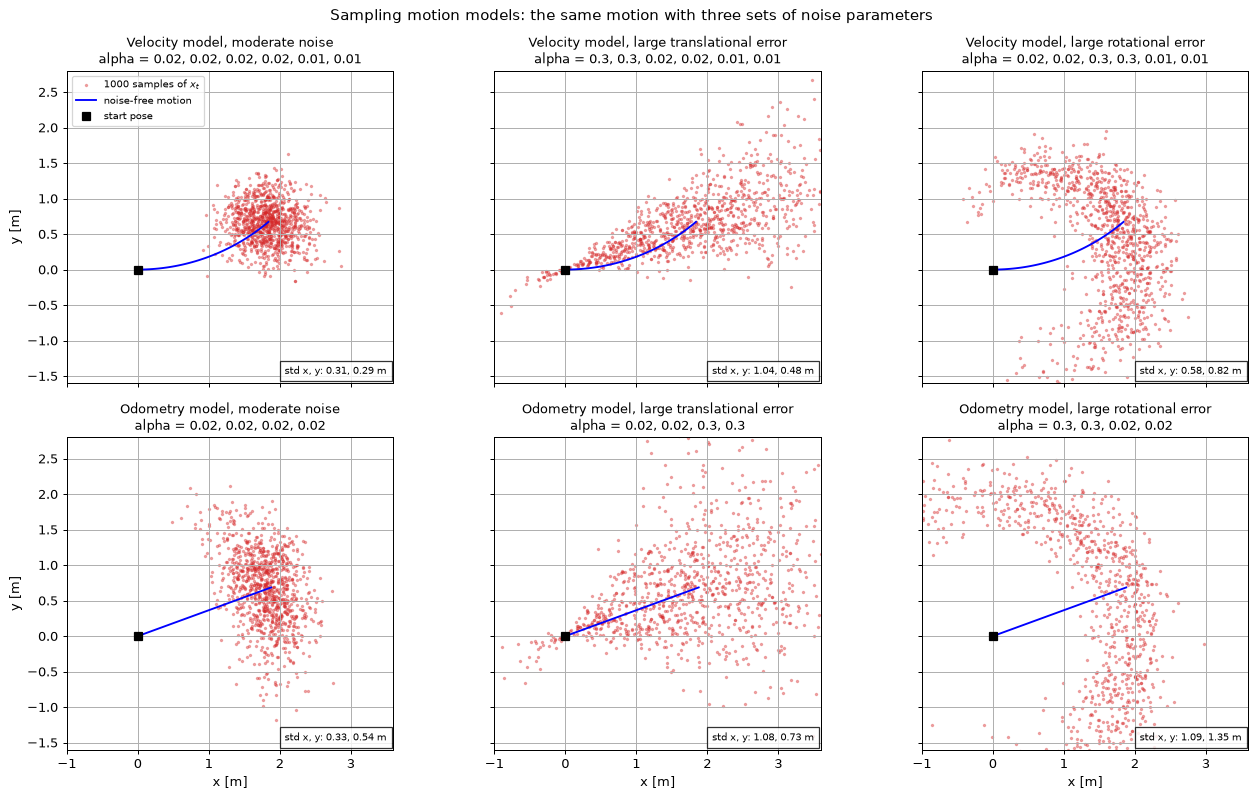

In [5]:
PRESETS = {
    "Moderate noise": ((0.02, 0.02, 0.02, 0.02, 0.01, 0.01), (0.02, 0.02, 0.02, 0.02)),
    "Large translational error": ((0.3, 0.3, 0.02, 0.02, 0.01, 0.01), (0.02, 0.02, 0.3, 0.3)),
    "Large rotational error": ((0.02, 0.02, 0.3, 0.3, 0.01, 0.01), (0.3, 0.3, 0.02, 0.02)),
}
fig, axes = plt.subplots(2, 3, figsize=(15, 9), sharex=True, sharey=True)
arc = np.linspace(0, DT, 50)
for col, (name, (a_vel, a_odo)) in enumerate(PRESETS.items()):
    clouds = [
        ("Velocity", sample_motion_model_velocity((V, OMEGA), START, a_vel, DT, 1000), a_vel,
         (V / OMEGA * np.sin(OMEGA * arc), V / OMEGA * (1 - np.cos(OMEGA * arc)))),
        ("Odometry", sample_motion_model_odometry(ODO, START, a_odo, 1000), a_odo,
         ([0, ODO[1][0]], [0, ODO[1][1]])),
    ]
    for row, (model, cloud, a, path) in enumerate(clouds):
        ax = axes[row, col]
        ax.scatter(cloud[0], cloud[1], s=3, c="tab:red", alpha=0.35, label="1000 samples of $x_t$")
        ax.plot(*path, "-b", lw=1.5, label="noise-free motion")
        ax.plot(0, 0, "ks", label="start pose")
        ax.set_title(f"{model} model, {name.lower()}\nalpha = {', '.join(f'{v:g}' for v in a)}", fontsize=10)
        ax.text(0.98, 0.03, f"std x, y: {cloud[0].std():.2f}, {cloud[1].std():.2f} m", transform=ax.transAxes,
                ha="right", fontsize=8, bbox={"fc": "white", "alpha": 0.8})
        ax.set_aspect("equal")
        ax.grid(True)
        ax.set_xlim(-1.0, 3.6)
        ax.set_ylim(-1.6, 2.8)
for ax in axes[1]:
    ax.set_xlabel("x [m]")
for ax in axes[:, 0]:
    ax.set_ylabel("y [m]")
axes[0, 0].legend(loc="upper left", fontsize=8)
fig.suptitle("Sampling motion models: the same motion with three sets of noise parameters")
plt.tight_layout()
plt.show()

### The misprint in line 7 of Table 5.1

Drive forward ($v > 0$) while turning right ($\omega < 0$), then ask the closed form how likely the exact noise-free end pose is. It should be the most likely pose of all.

In [6]:
u_right = (1.0, -0.35)
end = sample_motion_model_velocity(u_right, START, (0, 0, 0, 0, 0, 0), DT, 1)[:, 0]  # noise-free end pose
for printed in (True, False):
    p = motion_model_velocity(end, u_right, START, A_VEL, DT, printed_line7=printed)
    print(f"line 7 {'as printed' if printed else 'with signed radius'}: p(noise-free end pose) = {float(p):.3g}")

line 7 as printed: p(noise-free end pose) = 5.45e-38
line 7 with signed radius: p(noise-free end pose) = 26.7


## Part 2. Make it yours: the odometry model on Spot (Paper 2)

Trial `2026-05-29T11-15-47` of the Paper 2 experiment (`ros2_spot_crazyflie_crazyswarm2_apriltag_mocap`, Spot moves its body while the drone follows). Spot's own odometry (`/spot_BD_42910021/odometry`) is the control $u_t$, the motion capture pose of Spot's body is the ground truth. In this trial Spot walks **sideways**, left and right, with an almost constant heading. The odometry model was written for a robot that turns and then drives forward. What does it do with a robot that walks sideways?

The cell reads the slim MCAP bag directly, without ROS (the `mcap` and `mcap-ros2-support` packages). The bag is not part of this repository. Set `PAPER2_BAG` to another trial folder, or skip this part when the bag is not on your machine.

In [7]:
BAG = Path(os.environ.get("PAPER2_BAG", Path.home() / "git/lorite_ros2_humble_phd/experiments/ros2_spot_crazyflie_crazyswarm2_apriltag_mocap/bags_slim/2026-05-29T11-15-47_predefined_trajectory_mocap_slim"))
HAVE_BAG = BAG.exists() and any(BAG.glob("*.mcap"))
print("bag:", BAG.name if HAVE_BAG else f"not found, Part 2 is skipped ({BAG})")

if HAVE_BAG:
    from mcap.reader import make_reader
    from mcap_ros2.decoder import DecoderFactory

    def yaw(q):
        return math.atan2(2 * (q.w * q.z + q.x * q.y), 1 - 2 * (q.y**2 + q.z**2))

    odo, moc = [], []
    with open(next(BAG.glob("*.mcap")), "rb") as f:
        reader = make_reader(f, decoder_factories=[DecoderFactory()])
        for _, ch, msg, m in reader.iter_decoded_messages(topics=["/spot_BD_42910021/odometry", "/mocap/poses"]):
            t = msg.log_time * 1e-9
            if ch.topic == "/mocap/poses":
                moc += [(t, p.pose.position.x, p.pose.position.y, yaw(p.pose.orientation)) for p in m.poses if p.name == "spot_BD_42910021"]
            else:
                p = m.pose.pose
                odo.append((t, p.position.x, p.position.y, yaw(p.orientation)))
    odo, moc = np.array(odo), np.array(moc)
    t0 = odo[0, 0]

    # Steps of 0.5 s. Mocap is interpolated to the odometry times.
    ts = np.arange(odo[0, 0], odo[-1, 0], 0.5)
    O = np.vstack([np.interp(ts, odo[:, 0], odo[:, 1]), np.interp(ts, odo[:, 0], odo[:, 2]), wrap(np.interp(ts, odo[:, 0], np.unwrap(odo[:, 3])))])
    M = np.vstack([np.interp(ts, moc[:, 0], moc[:, 1]), np.interp(ts, moc[:, 0], moc[:, 2]), np.interp(ts, moc[:, 0], np.unwrap(moc[:, 3]))])
    # Express mocap in the odometry frame by aligning the first poses.
    dth = O[2, 0] - M[2, 0]
    c, s = math.cos(dth), math.sin(dth)
    dx, dy = M[0] - M[0, 0], M[1] - M[1, 0]
    M = np.vstack([O[0, 0] + c * dx - s * dy, O[1, 0] + s * dx + c * dy, wrap(M[2] + dth)])
    rot1, trans, rot2 = odometry_deltas(O[:, :-1], O[:, 1:])
    moving = trans >= MIN_TRANS
    print(f"{odo.shape[0]} odometry and {moc.shape[0]} mocap messages, {ts[-1] - ts[0]:.0f} s, {len(ts) - 1} steps of 0.5 s, {moving.sum()} of them with motion")
    print(f"odometry path {trans.sum():.2f} m, heading change {math.degrees(O[2].max() - O[2].min()):.0f} deg")
    print(f"|rot1| of the moving steps: median {math.degrees(np.median(np.abs(rot1[moving]))):.0f} deg")

bag: 2026-05-29T11-15-47_predefined_trajectory_mocap_slim


3003 odometry and 7188 mocap messages, 60 s, 120 steps of 0.5 s, 75 of them with motion
odometry path 4.58 m, heading change 15 deg
|rot1| of the moving steps: median 98 deg


### Which $\alpha$ does the data support?

The closed form gives a direct way to tune the noise: the best $\alpha$ makes the true motion (mocap) most likely given the odometry. Below we compute the mean log density of the 0.5 s mocap steps under Table 5.5 on a grid of two values: $k$ for $\alpha_1 = \alpha_2 = \alpha_3$, and $\alpha_4$ alone, the term that adds translational noise for every rotation. This is the maximum likelihood idea that section 5.4 only mentions.

best with one shared value: alpha_1..4 = 0.018
best with alpha_4 separate: alpha_1..3 = 0.018, alpha_4 = 1e-06


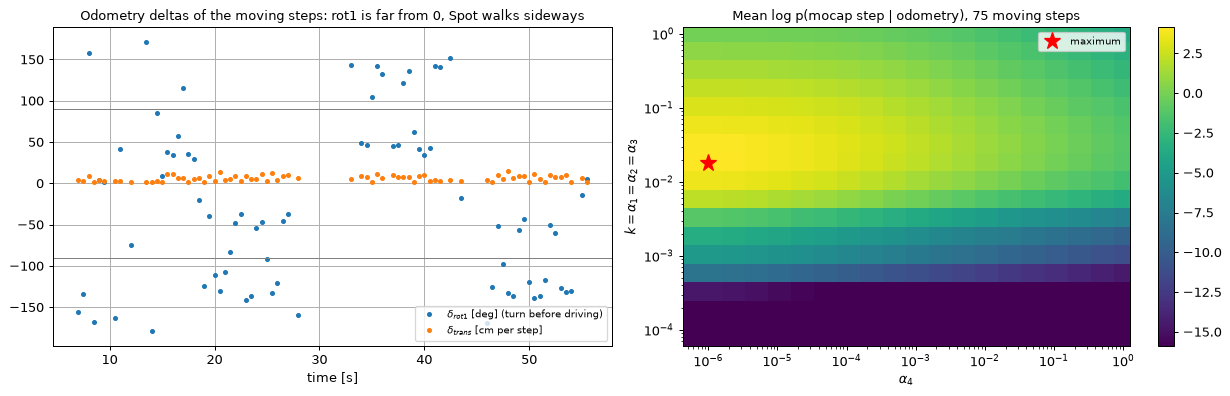

In [8]:
if HAVE_BAG:
    def mean_loglik(a):
        sel = (O[:, :-1][:, moving], O[:, 1:][:, moving])
        return np.mean(np.log(motion_model_odometry(M[:, 1:][:, moving], sel, M[:, :-1][:, moving], a) + 1e-300))

    ks = np.logspace(-4, 0, 17)
    a4s = np.logspace(-6, 0, 19)
    LL = np.array([[mean_loglik((k, k, k, a4)) for a4 in a4s] for k in ks])
    i, j = np.unravel_index(np.argmax(LL), LL.shape)
    best = (ks[i], ks[i], ks[i], a4s[j])
    shared = ks[np.argmax([mean_loglik((k, k, k, k)) for k in ks])]
    print(f"best with one shared value: alpha_1..4 = {shared:.2g}")
    print(f"best with alpha_4 separate: alpha_1..3 = {best[0]:.2g}, alpha_4 = {best[3]:.2g}")

    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
    ax.plot(ts[1:][moving] - ts[0], np.degrees(rot1[moving]), ".", label=r"$\delta_{rot1}$ [deg] (turn before driving)")
    ax.plot(ts[1:][moving] - ts[0], 100 * trans[moving], ".", label=r"$\delta_{trans}$ [cm per step]")
    for h in (-90, 90):
        ax.axhline(h, color="gray", lw=0.8)
    ax.set_xlabel("time [s]")
    ax.set_title("Odometry deltas of the moving steps: rot1 is far from 0, Spot walks sideways", fontsize=10)
    ax.legend(fontsize=8)
    ax.grid(True)
    im = ax2.pcolormesh(a4s, ks, np.maximum(LL, LL.max() - 20), shading="nearest", cmap="viridis")
    ax2.plot(best[3], best[0], "r*", ms=14, label="maximum")
    ax2.set_xscale("log")
    ax2.set_yscale("log")
    ax2.set_xlabel(r"$\alpha_4$")
    ax2.set_ylabel(r"$k = \alpha_1 = \alpha_2 = \alpha_3$")
    ax2.set_title(f"Mean log p(mocap step | odometry), {moving.sum()} moving steps", fontsize=10)
    ax2.legend(fontsize=8)
    fig.colorbar(im, ax=ax2)
    plt.tight_layout()
    plt.show()

### The clouds: book-style $\alpha$ against the fitted $\alpha$

Both panels run Table 5.6 for 60 s on Spot's odometry with 300 samples. Left: all four $\alpha_i$ = 0.02, the moderate preset of Part 1. Right: the maximum of the scan above. Note the different scales of the two panels.

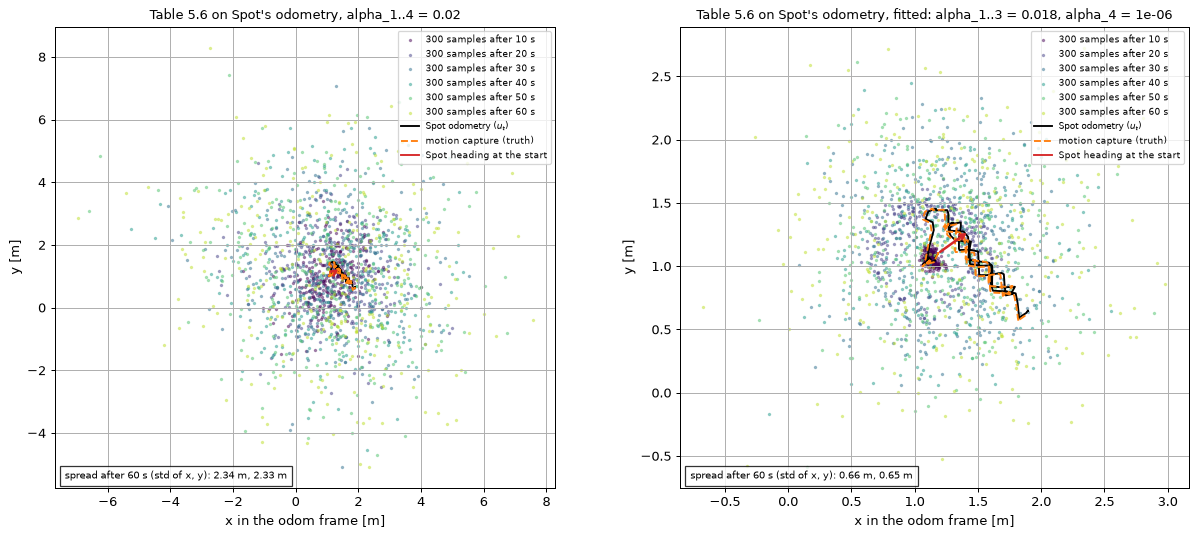

In [9]:
if HAVE_BAG:
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    for ax, a_spot, title in ((axes[0], (0.02, 0.02, 0.02, 0.02), "alpha_1..4 = 0.02"),
                              (axes[1], best, f"fitted: alpha_1..3 = {best[0]:.2g}, alpha_4 = {best[3]:.2g}")):
        cloud = np.tile(O[:, :1], (1, 300))
        snaps = {int(k) for k in np.linspace(0, len(ts) - 1, 7)[1:]}
        colors = iter(plt.cm.viridis(np.linspace(0, 0.9, len(snaps))))
        for k in range(len(ts) - 1):
            cloud = sample_motion_model_odometry((O[:, k], O[:, k + 1]), cloud, a_spot, cloud.shape[1])
            if k + 1 in snaps:
                ax.scatter(cloud[0], cloud[1], s=3, alpha=0.4, color=next(colors), label=f"300 samples after {ts[k + 1] - ts[0]:.0f} s")
        ax.plot(O[0], O[1], "-k", lw=1.5, label="Spot odometry ($u_t$)")
        ax.plot(M[0], M[1], "--", color="tab:orange", lw=1.5, label="motion capture (truth)")
        ax.annotate("", xy=(O[0, 0] + 0.3 * math.cos(O[2, 0]), O[1, 0] + 0.3 * math.sin(O[2, 0])), xytext=(O[0, 0], O[1, 0]),
                    arrowprops={"arrowstyle": "->", "lw": 2, "color": "tab:red"})
        ax.plot([], [], color="tab:red", label="Spot heading at the start")
        ax.text(0.02, 0.02, f"spread after 60 s (std of x, y): {cloud[0].std():.2f} m, {cloud[1].std():.2f} m", transform=ax.transAxes,
                fontsize=8, bbox={"fc": "white", "alpha": 0.8})
        ax.set_aspect("equal")
        ax.set_xlabel("x in the odom frame [m]")
        ax.set_ylabel("y [m]")
        ax.grid(True)
        ax.legend(fontsize=7, loc="upper right")
        ax.set_title(f"Table 5.6 on Spot's odometry, {title}", fontsize=10)
    plt.tight_layout()
    plt.show()

## Part 3. Questions for the reading group

1. **The banana.** In the velocity model, why does "large rotational error" bend the cloud along the arc, and "large translational error" stretch it along the direction of travel? Which line of Table 5.3 makes each happen?
2. **Density against sampler.** The histogram filter needs Table 5.1, the particle filter needs only Table 5.3. Why is the sampler so much shorter (no circle reconstruction)? Which filter would you rather implement for a new robot whose motion model you can only simulate?
3. **The final rotation $\hat\gamma$.** Without it, what would the density over $\theta$ look like for a fixed $(x, y)$? (Hint: Part 1 adds up 241 headings per cell. Count how many would be nonzero.)
4. **The missing Jacobian.** The tables' outputs integrate to about 7.6 (velocity) and 2.2 (odometry) over the pose, not to 1. Why does a histogram filter still work with them? When would it matter (hint: comparing two different motion models by their likelihood)?
5. **Spot walks sideways.** In the Spot run, $|\delta_{rot1}|$ has a median of about 98 degrees. Line 6 of Table 5.6 then makes the translational noise grow with $\alpha_4 \delta_{rot1}^2$, although Spot hardly turned (15 degrees in 60 s). With all $\alpha_i$ = 0.02 the cloud spreads 2.3 m in 60 s, while odometry and mocap stay within a few centimeters. The data wants $\alpha_4$ near zero (the scan is flat below about $10^{-3}$). Is the odometry model wrong for legged robots, or only badly parameterized? What would a model for an omnidirectional robot look like (three independent velocities $v_x, v_y, \omega$, as in the Nav2 AMCL omni model)?
6. **Tuning.** The scan fits $\alpha$ for 0.5 s steps. Would the best values change if the filter ran at 50 Hz instead of 2 Hz? (Compare "1 step" against "10 short steps" in the demo.)

## Part 4. Now read

With the plots above in mind, read in this order:

- 5.1 and 5.2 (pp. 117 to 121): the kinematic configuration and why a motion model is a probability density.
- 5.3 (velocity model): Table 5.1 (p. 123) with the line-7 misprint above, Table 5.3 (p. 124), and the derivation of the circle (eqs. 5.13 to 5.25). Compare Figs. 5.3 and 5.4 with the banana plot.
- 5.4 (odometry model): Tables 5.5 (p. 134) and 5.6 (p. 136), Fig. 5.7 (rotate, translate, rotate), and the remark on angle wrapping (p. 135).
- 5.5 (motion and maps): Table 5.7 (p. 141), the approximation of eq. 5.48.

The presenter's reading guide and the line-by-line notes of every table are in the vault's literature note for the book (section "Session 6 (2026-11-11): Alejandro presents chapter 5").